<a href="https://colab.research.google.com/github/ha616-cell/amml-2627/blob/main/Copy_of_AMML_Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3: Residual networks (ResNets)

The purpose of this notebook is to adapt neural networks for MNIST1D to use residual connections.. You will also implement pre-trained ResNets using the PyTorch library.

Work through the cells below, running each cell in turn. In various places you will see the words "TODO". Follow the instructions at these places and write code to complete the functions. There are also questions interspersed in the text.

Where an equation number is referenced, please consult the book "Understanding Deep Learning" (link to digital copy on Canvas).

In [ ]:
# Run this if you're in Colab to install MNIST 1D repository, else use uv in your environment instead
!pip install git+https://github.com/greydanus/mnist1d

  Cloning https://github.com/greydanus/mnist1d to /tmp/pip-req-build-d_vbu8kq
  Running command git clone --filter=blob:none --quiet https://github.com/greydanus/mnist1d /tmp/pip-req-build-d_vbu8kq
  Resolved https://github.com/greydanus/mnist1d to commit e2f536fa86442c13473b433d579e9852ec4d1c1d
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import os
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import matplotlib.pyplot as plt
import mnist1d
import random

random.seed(42)

In [ ]:
args = mnist1d.data.get_dataset_args()
data = mnist1d.data.get_dataset(args, path='./mnist1d_data.pkl', download=False, regenerate=False)

# The training and test input and outputs are in
# data['x'], data['y'], data['x_test'], and data['y_test']
print("Examples in training set: {}".format(len(data['y'])))
print("Examples in test set: {}".format(len(data['y_test'])))
print("Length of each example: {}".format(data['x'].shape[-1]))

Successfully loaded data from ./mnist1d_data.pkl
Examples in training set: 4000
Examples in test set: 1000
Length of each example: 40


In [ ]:
# Load in the data
train_data_x = data['x'].transpose()
train_data_y = data['y']
val_data_x = data['x_test'].transpose()
val_data_y = data['y_test']
# Print out sizes
print("Train data: %d examples (columns), each of which has %d dimensions (rows)"%((train_data_x.shape[1],train_data_x.shape[0])))
print("Validation data: %d examples (columns), each of which has %d dimensions (rows)"%((val_data_x.shape[1],val_data_x.shape[0])))

Train data: 4000 examples (columns), each of which has 40 dimensions (rows)
Validation data: 1000 examples (columns), each of which has 40 dimensions (rows)


Define the network

In [ ]:
# There are 40 input dimensions and 10 output dimensions for this data
# The inputs correspond to the 40 offsets in the MNIST1D template.
D_i = 40
# The outputs correspond to the 10 digits
D_o = 10


# We will adapt this model to have residual connections around the linear layers
# This is the same model we used in practical 8.1, but we can't use the sequential
# class for residual networks (which aren't strictly sequential).  Hence, I've rewritten
# it as a model that inherits from a base class

class ResidualNetwork(torch.nn.Module):
  def __init__(self, input_size, output_size, hidden_size=100):
    super(ResidualNetwork, self).__init__()
    self.linear1 = nn.Linear(input_size, hidden_size)
    self.linear2 = nn.Linear(hidden_size, hidden_size)
    self.linear3 = nn.Linear(hidden_size, hidden_size)
    self.linear4 = nn.Linear(hidden_size, output_size)
    print("Initialized MLPBase model with {} parameters".format(self.count_params()))

  def count_params(self):
    return sum([p.view(-1).shape[0] for p in self.parameters()])

# TODO -- Add residual connections to this model
# The order of operations within each block should similar to figure 11.5b
# ie., linear1 first, ReLU+linear2 in first residual block, ReLU+linear3 in second residual block), linear4 at end
# Replace this function
#  def forward(self, x):
#   return 0

  def forward(self, x):
    # Initial linear layer
    x = self.linear1(x)

    # First residual block
    residual = x
    x = torch.relu(x)
    x = self.linear2(x)
    x = x + residual

    # Second residual block
    residual = x
    x = torch.relu(x)
    x = self.linear3(x)
    x = x + residual

    # Final output layer
    x = self.linear4(x)

    return x



Now write a similar function, but with batch norm.

In [ ]:
# TODO Adapt the residual network above to add a batch norm operation
# before the contents of each residual link as in figure 11.6c in the book
# Use the torch function nn.BatchNorm1d
class ResidualNetworkWithBatchNorm(torch.nn.Module):
    def __init__(self, input_size, output_size, hidden_size=100):
        super(ResidualNetworkWithBatchNorm, self).__init__()

        self.linear1 = nn.Linear(input_size, hidden_size)
        self.bn1 = nn.BatchNorm1d(hidden_size)

        self.linear2 = nn.Linear(hidden_size, hidden_size)
        self.bn2 = nn.BatchNorm1d(hidden_size)

        self.linear3 = nn.Linear(hidden_size, hidden_size)
        self.bn3 = nn.BatchNorm1d(hidden_size)

        self.linear4 = nn.Linear(hidden_size, output_size)

    def count_params(self):
        return sum(p.numel() for p in self.parameters())

    def forward(self, x):
        print_variance("Input", x)

        # Initial linear layer
        x = self.linear1(x)
        print_variance("After linear1", x)

        # First residual block
        residual = x
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.linear2(x)
        x = x + residual
        print_variance("After residual block 1", x)

        # Second residual block
        residual = x
        x = self.bn2(x)
        x = torch.relu(x)
        x = self.linear3(x)
        x = x + residual
        print_variance("After residual block 2", x)

        # Final output layer
        x = self.linear4(x)
        print_variance("Output", x)

        return x

Define an initalisation routine for the weights and biases.

In [ ]:
# He initialization of weights
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

Train the ResidualNetwork.

In [ ]:
#Define the model
model = ResidualNetwork(40, 10)

# choose cross entropy loss function (equation 5.24 in the loss notes)
loss_function = nn.CrossEntropyLoss()
# construct SGD optimizer and initialize learning rate and momentum
optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)
# object that decreases learning rate by half every 20 epochs
scheduler = StepLR(optimizer, step_size=20, gamma=0.5)
# convert data to torch tensors
x_train = torch.tensor(train_data_x.transpose().astype('float32'))
y_train = torch.tensor(train_data_y.astype('long'))
x_val= torch.tensor(val_data_x.transpose().astype('float32'))
y_val = torch.tensor(val_data_y.astype('long'))

# load the data into a class that creates the batches
data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=100, shuffle=True, worker_init_fn=np.random.seed(1))

# Initialize model weights
model.apply(weights_init)

# loop over the dataset n_epoch times
n_epoch = 100
# store the loss and the % correct at each epoch
losses_train = np.zeros((n_epoch))
errors_train = np.zeros((n_epoch))
losses_val = np.zeros((n_epoch))
errors_val = np.zeros((n_epoch))

for epoch in range(n_epoch):
  # loop over batches
  for i, data in enumerate(data_loader):
    # retrieve inputs and labels for this batch
    x_batch, y_batch = data
    # zero the parameter gradients
    optimizer.zero_grad()
    # forward pass -- calculate model output
    pred = model(x_batch)
    # compute the loss
    loss = loss_function(pred, y_batch)
    # backward pass
    loss.backward()
    # SGD update
    optimizer.step()

  # Run whole dataset to get statistics -- normally wouldn't do this
  pred_train = model(x_train)
  pred_val = model(x_val)
  _, predicted_train_class = torch.max(pred_train.data, 1)
  _, predicted_val_class = torch.max(pred_val.data, 1)
  errors_train[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
  errors_val[epoch]= 100 - 100 * (predicted_val_class == y_val).float().sum() / len(y_val)
  losses_train[epoch] = loss_function(pred_train, y_train).item()
  losses_val[epoch]= loss_function(pred_val, y_val).item()
  print(f'Epoch {epoch:5d}, train loss {losses_train[epoch]:.6f}, train error {errors_train[epoch]:3.2f},  val loss {losses_val[epoch]:.6f}, percent error {errors_val[epoch]:3.2f}')

  # tell scheduler to consider updating learning rate
  scheduler.step()

Initialized MLPBase model with 25310 parameters
Epoch     0, train loss 1.617135, train error 59.35,  val loss 1.665383, percent error 62.40
Epoch     1, train loss 1.159637, train error 44.55,  val loss 1.361763, percent error 51.90
Epoch     2, train loss 0.981507, train error 36.35,  val loss 1.176178, percent error 45.30
Epoch     3, train loss 0.889572, train error 33.60,  val loss 1.134673, percent error 43.70
Epoch     4, train loss 0.815341, train error 31.18,  val loss 1.188875, percent error 45.10
Epoch     5, train loss 0.804818, train error 30.70,  val loss 1.161601, percent error 41.80
Epoch     6, train loss 0.738431, train error 28.68,  val loss 1.223548, percent error 43.40
Epoch     7, train loss 0.620215, train error 22.80,  val loss 1.167572, percent error 42.40
Epoch     8, train loss 0.526508, train error 19.72,  val loss 1.121012, percent error 37.90
Epoch     9, train loss 0.574784, train error 21.57,  val loss 1.228418, percent error 39.80
Epoch    10, train los

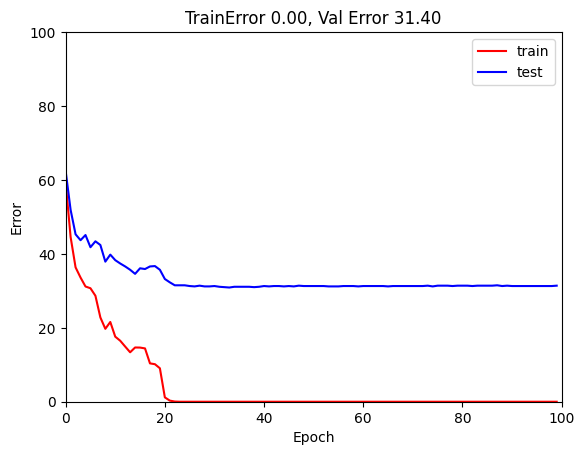

In [ ]:
# Plot the results
fig, ax = plt.subplots()
ax.plot(errors_train,'r-',label='train')
ax.plot(errors_val,'b-',label='test')
ax.set_ylim(0,100); ax.set_xlim(0,n_epoch)
ax.set_xlabel('Epoch'); ax.set_ylabel('Error')
ax.set_title('TrainError %3.2f, Val Error %3.2f'%(errors_train[-1],errors_val[-1]))
ax.legend()
plt.show()

The primary motivation of residual networks is to allow training of much deeper networks.   

TODO: Try running this network with and without the residual connections.  Does adding the residual connections change the performance?

TODO: Do the same as above, but with the batch norm version.

**Extension task**

Try running the deep convolutional 1D ResNet below. How does it perform with respect to the non-convolutional network above?

In [ ]:
# based on code from https://github.com/yannTrm/resnet_1D
import torch
import torch.nn as nn

class Block1D(nn.Module):
    """
    1D Residual Block for ResNet1D.

    This block consists of a series of convolutional and batch normalization layers,
    along with a skip connection.

    Parameters:
        - in_channels (int): Number of input channels.
        - intermediate_channels (int): Number of intermediate channels for convolutional layers.
        - identity_downsample (nn.Sequential): Skip connection to adjust dimensions if necessary.
        - stride (int): Stride for convolutional layers.
    """
    expansion = 4

    def __init__(self, in_channels:int, intermediate_channels:int, identity_downsample:nn.Sequential=None, stride:int=1):
        super(Block1D, self).__init__()
        self.conv1 = nn.Conv1d(in_channels, intermediate_channels, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn1 = nn.BatchNorm1d(intermediate_channels)
        self.conv2 = nn.Conv1d(intermediate_channels, intermediate_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(intermediate_channels)
        self.conv3 = nn.Conv1d(intermediate_channels, intermediate_channels * self.expansion, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn3 = nn.BatchNorm1d(intermediate_channels * self.expansion)
        self.relu = nn.ReLU()
        self.identity_downsample = identity_downsample
        self.stride = stride

    def forward(self, x):
        identity = x

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))

        if self.identity_downsample is not None:
            identity = self.identity_downsample(identity)

        out += identity
        out = self.relu(out)
        return out

class ResNet1D(nn.Module):
    """
    1D Convolutional Neural Network (CNN) based on ResNet for sequence data.

    Parameters:
        - block (nn.Module): Type of residual block to use (e.g., Block1D).
        - layers (list): List specifying the number of residual blocks in each layer.
        - input_channels (int): Number of input channels.
        - num_classes (int): Number of output classes.
    """
    def __init__(self, block:nn.Module, layers:list, input_channels:int, num_classes:int):
        super(ResNet1D, self).__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv1d(input_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(64)
        self.relu = nn.ReLU()
        self.layer1 = self._make_layer(block, 64, layers[0], stride=1)
        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(64 * block.expansion, num_classes)

    def _make_layer(self, block:nn.Module, intermediate_channels:int, num_blocks:int, stride:int):
        """
        Creates a layer of residual blocks.

        Parameters:
            - block (nn.Module): Type of residual block to use (e.g., Block1D).
            - intermediate_channels (int): Number of intermediate channels for convolutional layers.
            - num_blocks (int): Number of residual blocks in the layer.
            - stride (int): Stride for convolutional layers.
        """
        identity_downsample = None
        layers = []

        if stride != 1 or self.in_channels != intermediate_channels * block.expansion:
            identity_downsample = nn.Sequential(
                nn.Conv1d(self.in_channels, intermediate_channels * block.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(intermediate_channels * block.expansion)
            )

        layers.append(block(self.in_channels, intermediate_channels, identity_downsample, stride))
        self.in_channels = intermediate_channels * block.expansion

        for _ in range(1, num_blocks):
            layers.append(block(self.in_channels, intermediate_channels))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

def ResNet1_1D(input_channels:int=1, num_classes:int=2):
    """
    Constructs a ResNet with 1 block for 1D sequence data classification.

    Parameters:
        - input_channels (int, optional): Number of input channels (default: 1).
        - num_classes (int, optional): Number of output classes (default: 2).

    Returns:
        - ResNet1D: ResNet-18 model configured for 1D sequence data.
    """
    return ResNet1D(Block1D, [1, 0, 0, 0], input_channels, num_classes)

In [ ]:
model = ResNet1_1D(40, 10)
print ('Initialised deep ResNet with {} parameters'.format(sum([p.view(-1).shape[0] for p in model.parameters()])))
# choose cross entropy loss function (equation 5.24 in the loss notes)
loss_function = nn.CrossEntropyLoss()
# construct SGD optimizer and initialize learning rate and momentum
optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)
# object that decreases learning rate by half every 20 epochs
scheduler = StepLR(optimizer, step_size=20, gamma=0.5)
# convert data to torch tensors
x_train = torch.tensor(train_data_x.transpose().astype('float32'))
y_train = torch.tensor(train_data_y.astype('long'))
x_val= torch.tensor(val_data_x.transpose().astype('float32'))
y_val = torch.tensor(val_data_y.astype('long'))

# load the data into a class that creates the batches
batch_size=100
data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=batch_size, shuffle=True, worker_init_fn=np.random.seed(1))

# Initialize model weights
model.apply(weights_init)

# loop over the dataset n_epoch times
n_epoch = 100
# store the loss and the % correct at each epoch
losses_train = np.zeros((n_epoch))
errors_train = np.zeros((n_epoch))
losses_val = np.zeros((n_epoch))
errors_val = np.zeros((n_epoch))

for epoch in range(n_epoch):
  # loop over batches
  for i, data in enumerate(data_loader):
    # retrieve inputs and labels for this batch
    x_batch, y_batch = data
    # zero the parameter gradients
    optimizer.zero_grad()
    # forward pass -- calculate model output
    pred = model(x_batch.reshape(batch_size,40,1))
    # compute the loss
    loss = loss_function(pred, y_batch)
    # backward pass
    loss.backward()
    # SGD update
    optimizer.step()
    #
  # Run whole dataset to get statistics -- normally wouldn't do this
  pred_train = model(x_train.reshape(4000,40,1))
  pred_val = model(x_val.reshape(1000,40,1))
  _, predicted_train_class = torch.max(pred_train.data, 1)
  _, predicted_val_class = torch.max(pred_val.data, 1)
  errors_train[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
  errors_val[epoch]= 100 - 100 * (predicted_val_class == y_val).float().sum() / len(y_val)
  losses_train[epoch] = loss_function(pred_train, y_train).item()
  losses_val[epoch]= loss_function(pred_val, y_val).item()
  print(f'Epoch {epoch:5d}, train loss {losses_train[epoch]:.6f}, train error {errors_train[epoch]:3.2f},  val loss {losses_val[epoch]:.6f}, percent error {errors_val[epoch]:3.2f}')

  # tell scheduler to consider updating learning rate
  scheduler.step()

Initialised deep ResNet with 71050 parameters
Epoch     0, train loss 1.365631, train error 53.15,  val loss 1.469217, percent error 57.20
Epoch     1, train loss 1.361254, train error 52.72,  val loss 1.561132, percent error 59.90
Epoch     2, train loss 1.104576, train error 43.33,  val loss 1.314718, percent error 51.50
Epoch     3, train loss 1.127601, train error 42.30,  val loss 1.394805, percent error 52.70
Epoch     4, train loss 0.949475, train error 36.00,  val loss 1.261985, percent error 49.20
Epoch     5, train loss 0.891110, train error 33.80,  val loss 1.212475, percent error 46.10
Epoch     6, train loss 0.802277, train error 29.78,  val loss 1.230622, percent error 46.90
Epoch     7, train loss 0.727900, train error 26.53,  val loss 1.194995, percent error 44.10
Epoch     8, train loss 0.695256, train error 25.10,  val loss 1.200012, percent error 43.70
Epoch     9, train loss 0.611516, train error 21.72,  val loss 1.124701, percent error 42.10
Epoch    10, train loss 